<a href="https://colab.research.google.com/github/gi-junqueira/Calculo-Numerico/blob/main/Tarefa_interpolacao_erro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Tarefa Interpolação Erros

Feito por: Giovanna Maria de Siqueira Junqueira

RA: 185218

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator, interp1d, CubicSpline, make_smoothing_spline
from matplotlib.patches import Rectangle

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (9, 5)
L = 6.0  # comprimento da barra, m

def temperatura_real(x):
    """Perfil analítico de referência em °C; x é dado em metros."""
    x = np.asarray(x, dtype=float)
    xi = x/L
    return 18 + 2.4*xi + 2.5*np.sin(np.pi*xi)

x_min, x_max = 0.0, L
x_fino = np.linspace(x_min, x_max, 2001)
T_fino = temperatura_real(x_fino)

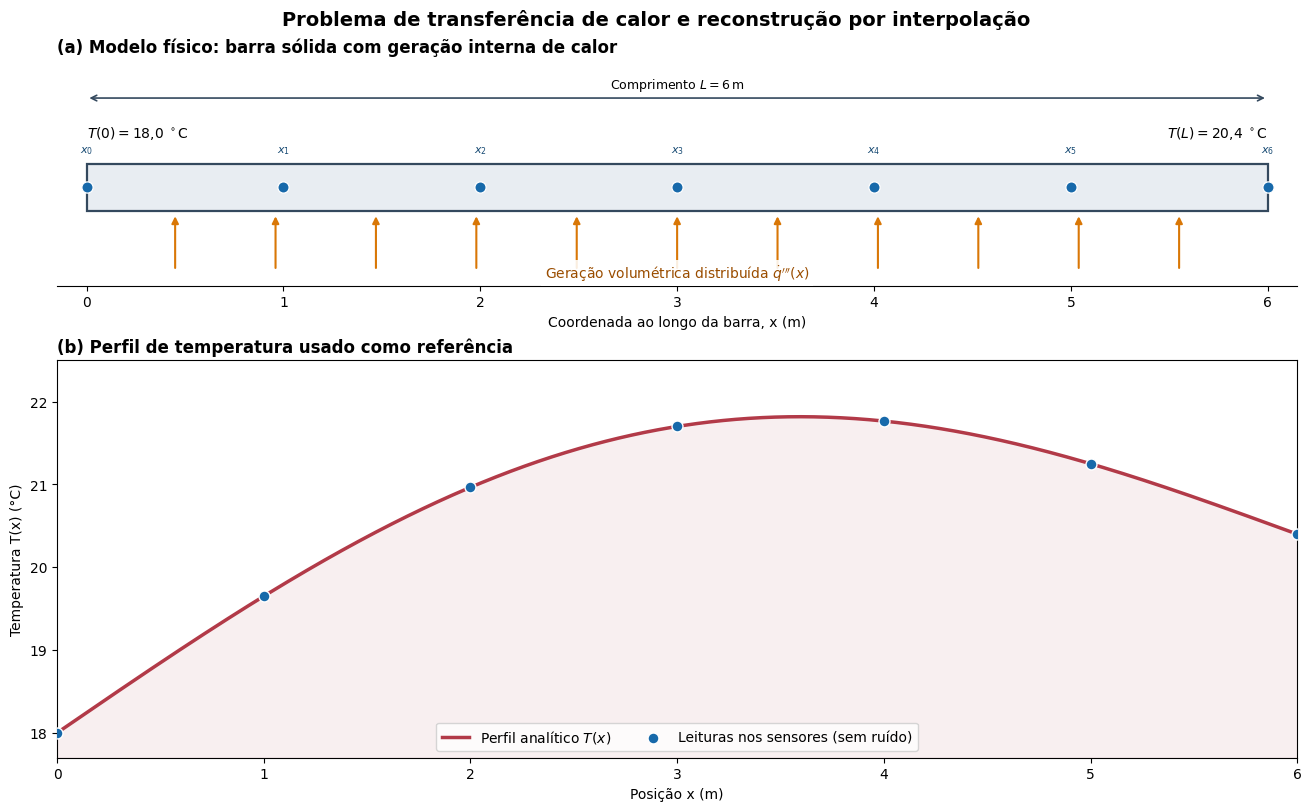

T(0)=18.0 °C, T(L)=20.4 °C; máximo T=21.818 °C em x=3.594 m


In [ ]:
# Figura do problema: esquema físico e perfil analítico em painéis separados
x_sensores_fig = np.linspace(0, L, 7)
T_sensores_fig = temperatura_real(x_sensores_fig)

fig = plt.figure(figsize=(13, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[0.85, 1.5])
ax_esq = fig.add_subplot(gs[0]); ax_perfil = fig.add_subplot(gs[1])

ax_esq.set_title("(a) Modelo físico: barra sólida com geração interna de calor", loc="left", fontsize=12, weight="bold")
barra_y, barra_h = 0.40, 0.25
ax_esq.add_patch(Rectangle((0, barra_y), L, barra_h, facecolor="#e8edf2",
                           edgecolor="#34495e", linewidth=1.6, zorder=1))
ax_esq.scatter(x_sensores_fig, np.full_like(x_sensores_fig, barra_y+barra_h/2),
               s=65, marker="o", facecolor="#1769aa", edgecolor="white", linewidth=0.9, zorder=4)
for xpos in np.linspace(0.45, 5.55, 11):
    ax_esq.annotate("", xy=(xpos, barra_y-0.015), xytext=(xpos, 0.08),
                    arrowprops={"arrowstyle":"-|>", "color":"#d97706", "lw":1.5}, zorder=3)
ax_esq.text(L/2, 0.015, r"Geração volumétrica distribuída $\dot{q}^{\prime\prime\prime}(x)$",
            ha="center", va="bottom", color="#9a4d00", fontsize=10,
            bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.88, "pad":2.5})
ax_esq.text(0, 0.77, r"$T(0)=18{,}0\ ^\circ\mathrm{C}$", ha="left", va="bottom", fontsize=10)
ax_esq.text(L, 0.77, r"$T(L)=20{,}4\ ^\circ\mathrm{C}$", ha="right", va="bottom", fontsize=10)
ax_esq.annotate("", xy=(L, 1.00), xytext=(0, 1.00), arrowprops={"arrowstyle":"<->", "color":"#34495e", "lw":1.2})
ax_esq.text(L/2, 1.025, r"Comprimento $L=6\,\mathrm{m}$", ha="center", va="bottom", fontsize=9)
for i, xpos in enumerate(x_sensores_fig):
    ax_esq.text(xpos, barra_y+barra_h+0.04, rf"$x_{i}$", ha="center", va="bottom", fontsize=8, color="#174a73")
ax_esq.set_xlim(-0.15, L+0.15); ax_esq.set_ylim(0, 1.2)
ax_esq.set_xlabel("Coordenada ao longo da barra, x (m)")
ax_esq.set_yticks([]); ax_esq.grid(False)
for spine in ["left", "right", "top"]: ax_esq.spines[spine].set_visible(False)

ax_perfil.set_title("(b) Perfil de temperatura usado como referência", loc="left", fontsize=12, weight="bold")
ax_perfil.plot(x_fino, T_fino, color="#b23a48", linewidth=2.5, label=r"Perfil analítico $T(x)$", zorder=2)
ax_perfil.scatter(x_sensores_fig, T_sensores_fig, s=62, facecolor="#1769aa", edgecolor="white",
                  label="Leituras nos sensores (sem ruído)", zorder=4)
ax_perfil.fill_between(x_fino, T_fino, np.min(T_fino)-0.3, color="#b23a48", alpha=0.08, zorder=1)
ax_perfil.set_xlim(0, L); ax_perfil.set_ylim(17.7, 22.5)
ax_perfil.set_xlabel("Posição x (m)"); ax_perfil.set_ylabel("Temperatura T(x) (°C)")
ax_perfil.legend(loc="lower center", ncol=2)
fig.suptitle("Problema de transferência de calor e reconstrução por interpolação", fontsize=14, weight="bold")
plt.show()
i_max = np.argmax(T_fino)
print(f"T(0)={temperatura_real(0):.1f} °C, T(L)={temperatura_real(L):.1f} °C; "
      f"máximo T={T_fino[i_max]:.3f} °C em x={x_fino[i_max]:.3f} m")

In [ ]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    for i in range(n):                       # S_i(x_i)=y_i
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    for i in range(n):                       # S_i(x_{i+1})=y_{i+1}
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    for i in range(n-1):                     # continuidade de S'
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    A[row, 2*n] = 1                          # c_0 = 0
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário com os interpoladores (callables) dos quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange, "Spline linear": linear,
            "Spline quadrática": quad, "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

def nos_chebyshev_lobatto(a, b, N):
    k = np.arange(N)
    z = np.cos(k*np.pi/(N-1))
    return np.sort((a+b)/2 + (b-a)*z/2)
print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## Etapa 1 — Interpolação com dados exatos
Sete sensores equiespaçados, incluindo as extremidades.

                  Método  Erro máximo (°C)  MAE (°C)  RMSE (°C)
0        Lagrange global          0.000085  0.000019   0.000033
1  Spline cúbica natural          0.000506  0.000184   0.000239
2      Spline quadrática          0.023927  0.014950   0.016466
3          Spline linear          0.082294  0.036510   0.043967

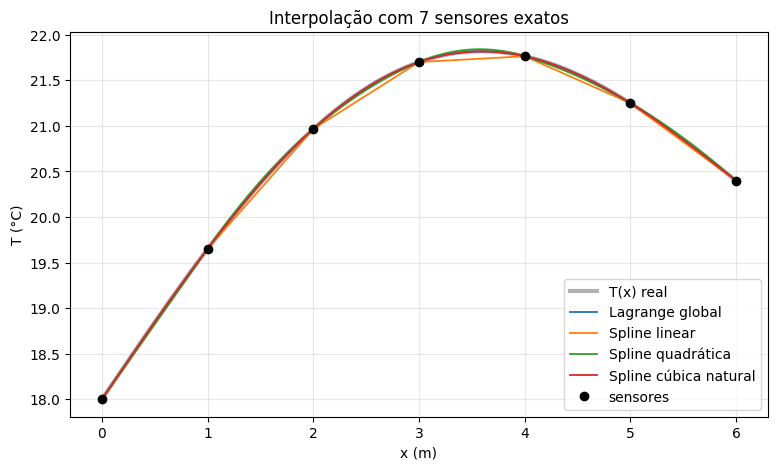

In [ ]:
x_nos_7 = np.linspace(x_min, x_max, 7)
y_nos_7 = temperatura_real(x_nos_7)
metodos_7 = criar_metodos(x_nos_7, y_nos_7)

metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
display(metricas_7)

plt.plot(x_fino, T_fino, "k", lw=3, alpha=0.3, label="T(x) real")
for nome, m in metodos_7.items():
    plt.plot(x_fino, m(x_fino), lw=1.3, label=nome)
plt.plot(x_nos_7, y_nos_7, "ko", label="sensores")
plt.xlabel("x (m)"); plt.ylabel("T (°C)"); plt.title("Interpolação com 7 sensores exatos")
plt.legend(); plt.grid(alpha=0.3); plt.show()

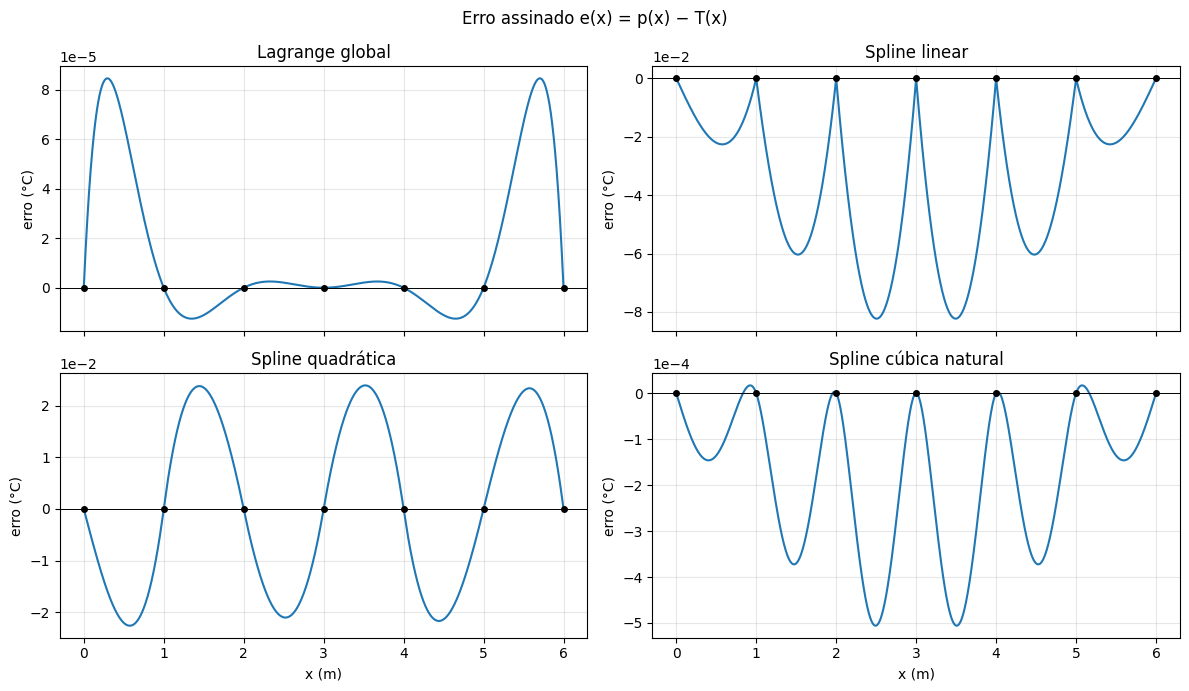

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, (nome, m) in zip(axs.ravel(), metodos_7.items()):
    erro = m(x_fino) - T_fino
    ax.plot(x_fino, erro)
    ax.plot(x_nos_7, np.zeros(7), "ko", ms=4)
    ax.axhline(0, color="k", lw=0.7)
    ax.set_title(nome); ax.set_ylabel("erro (°C)"); ax.grid(alpha=0.3)
    ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2))
for ax in axs[1]: ax.set_xlabel("x (m)")
plt.suptitle("Erro assinado e(x) = p(x) − T(x)"); plt.tight_layout(); plt.show()

## Etapa 2 — Número e posição dos sensores (Lagrange global)

In [ ]:
def nos_chebyshev_lobatto(a, b, N):
    k = np.arange(N)
    z = np.cos(k*np.pi/(N-1))
    return np.sort((a+b)/2 + (b-a)*z/2)

linhas = []
for N in [5, 9, 13, 17]:
    for dist, xn in [("Equiespaçado", np.linspace(x_min, x_max, N)),
                     ("Chebyshev", nos_chebyshev_lobatto(x_min, x_max, N))]:
        erro = BarycentricInterpolator(xn, temperatura_real(xn))(x_fino) - T_fino
        linhas.append({"N": N, "Nós": dist, "Erro máximo (°C)": np.max(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
tabela_nos = pd.DataFrame(linhas)
display(tabela_nos)

    N           Nós  Erro máximo (°C)     RMSE (°C)
0   5  Equiespaçado      4.530257e-03  2.159567e-03
1   5     Chebyshev      2.326599e-03  1.532697e-03
2   9  Equiespaçado      1.043537e-06  3.438146e-07
3   9     Chebyshev      2.167582e-07  1.202332e-07
4  13  Equiespaçado      5.911360e-11  1.545699e-11
5  13     Chebyshev      3.627321e-12  1.932157e-12
6  17  Equiespaçado      1.989520e-12  2.445428e-13
7  17     Chebyshev      1.421085e-14  3.841066e-15

**Conclusões da Etapa 2**
* Os dois tipos de nós convergem muito rápido: o erro máximo cai de ~10⁻³ °C ($N=5$) para ~10⁻¹² a 10⁻¹⁴ °C ($N=17$).
* Chebyshev é sempre melhor, e a diferença aumenta com $N$: cerca de 2× em $N=5$ e mais de 100× em $N=17$. Isso acontece porque os nós de Chebyshev ficam mais concentrados perto das pontas, justamente onde o erro dos nós equiespaçados é maior.
* Esse bom desempenho com nós equiespaçados vale para este perfil, que é muito suave (reta + seno). Para uma função menos suave, os nós equiespaçados poderiam oscilar bastante (fenômeno de Runge).

## Etapa 3 — Variação de $N$ de 4 a 40

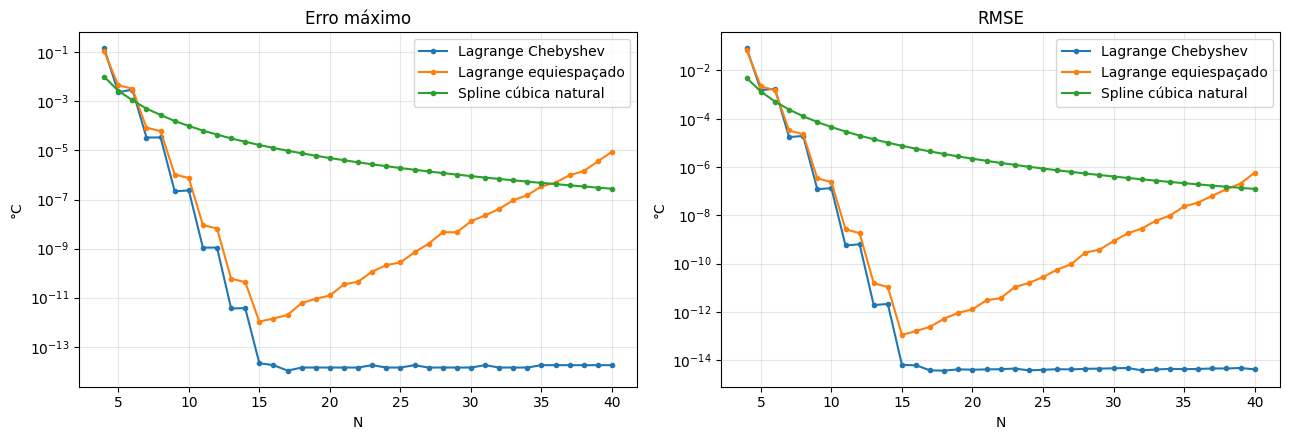

         Erro máximo (°C)                                              \
Método Lagrange Chebyshev Lagrange equiespaçado Spline cúbica natural   
N                                                                       
5            2.326599e-03          4.530257e-03          2.665219e-03   
10           2.337620e-07          7.516743e-07          9.963236e-05   
15           2.131628e-14          1.058709e-12          1.661096e-05   
20           1.421085e-14          1.227818e-11          4.899580e-06   
30           1.421085e-14          1.288403e-08          8.992694e-07   
40           1.776357e-14          8.854141e-06          2.745707e-07   

         t avaliação (ms)                                              
Método Lagrange Chebyshev Lagrange equiespaçado Spline cúbica natural  
N                                                                      
5                0.418737              0.438592              0.103457  
10               0.530005              0.563194       

In [ ]:
linhas = []
for N in range(4, 41):
    xe = np.linspace(x_min, x_max, N)
    xc = nos_chebyshev_lobatto(x_min, x_max, N)
    casos = {"Lagrange equiespaçado": (xe, BarycentricInterpolator),
             "Lagrange Chebyshev": (xc, BarycentricInterpolator),
             "Spline cúbica natural": (xe, lambda x, y: CubicSpline(x, y, bc_type="natural"))}
    for nome, (xn, construtor) in casos.items():
        yn = temperatura_real(xn)
        t0 = time.perf_counter(); interp = construtor(xn, yn); t1 = time.perf_counter()
        p = interp(x_fino); t2 = time.perf_counter()
        erro = p - T_fino
        linhas.append({"N": N, "Método": nome, "Erro máximo (°C)": np.max(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2)),
                       "t construção (ms)": 1e3*(t1-t0), "t avaliação (ms)": 1e3*(t2-t1)})
estudo = pd.DataFrame(linhas)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for nome, g in estudo.groupby("Método"):
    axs[0].semilogy(g.N, g["Erro máximo (°C)"], "o-", ms=3, label=nome)
    axs[1].semilogy(g.N, g["RMSE (°C)"], "o-", ms=3, label=nome)
axs[0].set_title("Erro máximo"); axs[1].set_title("RMSE")
for ax in axs: ax.set_xlabel("N"); ax.set_ylabel("°C"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

display(estudo[estudo.N.isin([5, 10, 15, 20, 30, 40])]
        .pivot(index="N", columns="Método", values=["Erro máximo (°C)", "t avaliação (ms)"]))

**Conclusões da Etapa 3**
* **Lagrange Chebyshev:** o erro cai exponencialmente e chega ao limite da precisão do computador (~10⁻¹⁴ °C) por volta de $N=15$, ficando estável até $N=40$.
* **Lagrange equiespaçado:** melhora até $N\approx15$ (~10⁻¹² °C) e depois **piora**, chegando a ~10⁻⁵ °C em $N=40$. Isso é instabilidade numérica: com nós equiespaçados, pequenos erros de arredondamento são muito amplificados quando $N$ é grande.
* **Spline cúbica natural:** o erro diminui de forma constante, proporcional a $h^4$ (~3×10⁻⁷ °C em $N=40$). Converge mais devagar que Chebyshev, mas é estável.
* **Custo:** construir qualquer um dos três é rápido. Avaliar o Lagrange fica mais caro conforme $N$ cresce (custo proporcional a $N$ por ponto); a spline mantém praticamente o mesmo tempo.
* **Existe um método melhor para todo $N$?** Não. A spline vence com pouquíssimos nós ($N=4$ e $6$), o Lagrange Chebyshev vence a partir de $N=7$, e com nós equiespaçados o Lagrange só é bom até $N\approx15$.

## Teste com ruído nos sensores
Leituras com ruído gaussiano de desvio-padrão σ = 0,05 °C, repetindo 100 vezes e tirando a média do RMSE. Incluí também uma spline de suavização, que não passa exatamente pelos pontos.

In [ ]:
sigma = 0.05
rng = np.random.default_rng(0)
linhas = []
for N in [7, 13, 25, 41]:
    xe = np.linspace(0, L, N); xc = nos_chebyshev_lobatto(0, L, N)
    rmse = {}
    for _ in range(100):
        ye = temperatura_real(xe) + rng.normal(0, sigma, N)
        yc = temperatura_real(xc) + rng.normal(0, sigma, N)
        metodos = {"Lagrange equiespaçado": BarycentricInterpolator(xe, ye),
                   "Lagrange Chebyshev": BarycentricInterpolator(xc, yc),
                   "Spline cúbica natural": CubicSpline(xe, ye, bc_type="natural"),
                   "Spline de suavização": make_smoothing_spline(xe, ye)}
        for nome, m in metodos.items():
            rmse.setdefault(nome, []).append(np.sqrt(np.mean((m(x_fino) - T_fino)**2)))
    for nome, v in rmse.items():
        linhas.append({"N": N, "Método": nome, "RMSE médio (°C)": np.mean(v)})
display(pd.DataFrame(linhas).pivot(index="Método", columns="N", values="RMSE médio (°C)"))

# Extrapolação: usando os 7 sensores exatos para estimar além da barra (6 a 8 m)
x_ext = np.linspace(L, L+2, 201)
for nome in ["Lagrange global", "Spline cúbica natural"]:
    e_ext = np.max(np.abs(metodos_7[nome](x_ext) - temperatura_real(x_ext)))
    e_int = metricas_7.set_index("Método").loc[nome, "Erro máximo (°C)"]
    print(f"{nome}: erro máx. dentro = {e_int:.1e} °C | fora (até 2 m) = {e_ext:.1e} °C")

N                            7         13          25            41
Método                                                             
Lagrange Chebyshev     0.048306  0.047394    0.049755  4.933676e-02
Lagrange equiespaçado  0.056287  0.387576  344.887262  8.022592e+06
Spline cúbica natural  0.043146  0.046431    0.045578  4.619518e-02
Spline de suavização   0.040100  0.033103    0.024157  1.980527e-02

Lagrange global: erro máx. dentro = 8.5e-05 °C | fora (até 2 m) = 6.3e-02 °C
Spline cúbica natural: erro máx. dentro = 5.1e-04 °C | fora (até 2 m) = 1.6e-02 °C


**Observações**
* Com ruído, os interpoladores passam exatamente pelas leituras e **copiam o ruído**: o RMSE fica perto de σ (~0,05 °C) mesmo aumentando $N$.
* O Lagrange equiespaçado **amplifica** o ruído e explode com muitos nós: RMSE de centenas de °C em $N=25$.
* A spline de suavização é a única que melhora com mais sensores, ficando abaixo do próprio σ com $N=41$.
* Fora da barra (extrapolação), o erro cresce muito em relação ao erro de dentro do intervalo.

## Etapa 4 — Recomendação técnica

**Poucos sensores exatos:** eu usaria a **spline cúbica**. Com 7 sensores o Lagrange teve erro um pouco menor (erro máximo 8×10⁻⁵ contra 5×10⁻⁴ °C), mas só porque o perfil é muito suave, algo que em campo não dá para garantir. A spline teve erro baixo e é mais segura: um problema em um sensor só afeta a região próxima dele. Eu evitaria a linear e a quadrática, que tiveram erros de 100 a 1000 vezes maiores.

**Mais sensores:** com nós equiespaçados, **não** usaria Lagrange global para $N$ grande, porque o erro máximo voltou a crescer depois de $N\approx15$. A spline cúbica continua melhorando (RMSE ~10⁻⁷ °C em $N=40$) e tem custo baixo. Se for possível escolher onde colocar os sensores, os nós de Chebyshev deixam o Lagrange estável e muito preciso.

**Sensores com ruído:** não usaria interpolação exata, porque ela reproduz o ruído (RMSE ≈ σ) e, no caso do Lagrange equiespaçado, o amplifica muito. Usaria um método que **suaviza** os dados, como a spline de suavização ou mínimos quadrados, que melhoram com mais sensores. Também estimaria o ruído dos sensores com medições repetidas.

**Extremidades:** é onde o Lagrange equiespaçado erra mais. Eu usaria as temperaturas conhecidas das pontas (18,0 °C e 20,4 °C), colocaria mais sensores perto das bordas e escolheria com cuidado a condição de contorno da spline. A natural funcionou bem aqui porque $T''=0$ nas pontas, mas isso nem sempre é verdade.

**Limitações sem a solução verdadeira:** em campo não é possível calcular erro máximo, MAE ou RMSE, porque $T(x)$ é desconhecida, e o erro nos sensores é sempre zero. Uma alternativa é retirar um sensor, prever o valor dele com os outros e comparar (validação cruzada). Os bons resultados aqui dependem de o perfil ser suave, e perfis reais podem não ser. Além disso, a interpolação só é confiável **dentro** do intervalo medido; na **extrapolação** o erro cresceu muito logo fora da barra, e para estimar além dos sensores seria preciso usar o modelo físico.